# MaxLFQ relative abundance

Recover sample-level protein changes despite unequal peptide responses and missing values.

For each pair of samples, take the median shared-peptide log ratio. Solve the resulting overdetermined linear system with the sample estimates centred at zero. This is the relative-abundance core of MaxLFQ. Absolute intensity rescaling is a separate step.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import maxlfq

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

centred log2 abundance [-0.8 -0.3  0.1  1. ]
RMSE 2.8066088919804617e-16


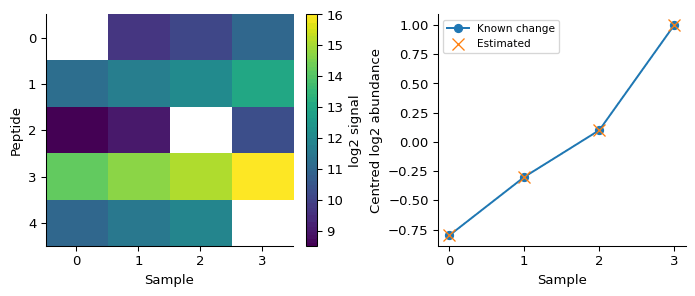

In [2]:
truth = np.array([-0.8, -0.3, 0.1, 1.0])
peptide = np.array([10.0, 12.0, 9.3, 15.0, 11.8])
logs = peptide[:, None] + truth
logs[0, 0] = np.nan
logs[2, 2] = np.nan
logs[4, 3] = np.nan
estimate = maxlfq(logs)
print("centred log2 abundance", estimate.round(4))
print("RMSE", np.sqrt(np.mean((estimate - truth) ** 2)))
assert np.allclose(estimate, truth)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3), constrained_layout=True)
im = a.imshow(logs, aspect="auto", cmap="viridis")
fig.colorbar(im, ax=a, label="log2 signal")
a.set(xlabel="Sample", ylabel="Peptide")
b.plot(truth, "o-", label="Known change")
b.plot(estimate, "x", ms=9, label="Estimated")
b.set(xlabel="Sample", ylabel="Centred log2 abundance")
b.legend(fontsize=8)
plt.show()

## Interpreting the result

Pairwise differences remove the peptide-specific offsets. Disconnected groups lack a ratio tying their abundance scales together.

## Exercise

Remove all peptide overlap between two sample groups and inspect the identifiability error.

## References

[Cox et al., MaxLFQ (2014)](https://doi.org/10.1074/mcp.M113.031591)